# Notebook 1 — Mecanismo de atención aplicado a una serie de tiempo


## 1. Marco conceptual

En una red recurrente clásica (RNN/GRU/LSTM) toda la historia de la serie se comprime en **un solo vector de estado** (el último estado oculto). Si la ventana es larga, información útil de pasos lejanos se diluye.

El **mecanismo de atención** permite que, al predecir, el modelo **consulte todos los pasos de la ventana** y decida cuánto pesa cada uno:

- **Query (Q):** lo que el modelo "pregunta" (aquí, el estado actual).
- **Key (K):** una "etiqueta" de cada paso de tiempo pasado.
- **Value (V):** el contenido de cada paso de tiempo.

Se calcula un puntaje de compatibilidad entre Q y cada K, se normaliza con *softmax* para obtener **pesos de atención** $\alpha_t$ (suman 1) y se construye un **vector de contexto** como promedio ponderado de los V:

$$\text{Atención}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V \qquad c=\sum_t \alpha_t\, v_t$$

En este notebook se implementan:
- La **atención de producto punto escalado** desde cero (ejemplo didáctico).
- Una **atención aditiva (Bahdanau)** sobre las salidas de una GRU para pronosticar temperatura, comparada con una GRU sin atención.

In [ ]:
import math, io, json, os, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

print("PyTorch:", torch.__version__, "| dispositivo:", device)
if device.type == "cpu":
    print("AVISO: activa una GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU")

PyTorch: 2.14.1+cpu | dispositivo: cpu
AVISO: activa una GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU


### Ejemplo mínimo: atención de producto punto escalado desde cero
Seis pasos de tiempo con embeddings aleatorios de dimensión 8. Cada paso actúa como *query*, *key* y *value* (auto-atención). La matriz resultante muestra a qué pasos "mira" cada posición.

Pesos (cada fila suma 1):
 [[0.61 0.06 0.02 0.1  0.03 0.18]
 [0.13 0.35 0.05 0.31 0.08 0.08]
 [0.01 0.01 0.95 0.   0.02 0.  ]
 [0.14 0.18 0.01 0.47 0.05 0.15]
 [0.13 0.16 0.22 0.17 0.23 0.1 ]
 [0.1  0.02 0.   0.06 0.01 0.8 ]]
Suma por fila: [1. 1. 1. 1. 1. 1.]


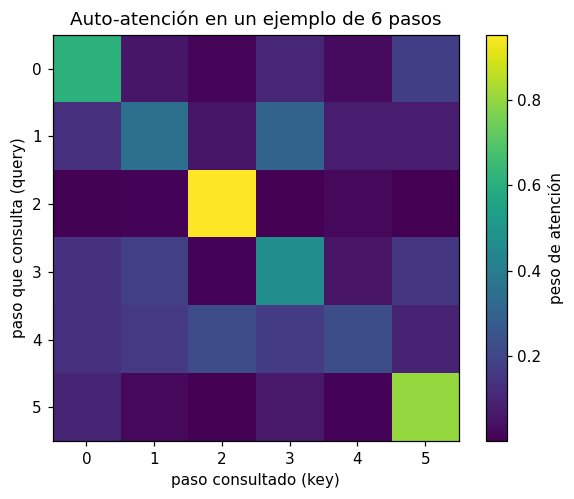

In [ ]:
def scaled_dot_product_attention(Q, K, V):
    d_k = Q.shape[-1]
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)   # compatibilidad Q·K, escalada
    weights = torch.softmax(scores, dim=-1)             # cada fila suma 1
    return weights @ V, weights

torch.manual_seed(0)
x = torch.randn(6, 8)                                   # 6 pasos, dimensión 8
out, w = scaled_dot_product_attention(x, x, x)
print("Pesos (cada fila suma 1):\n", w.numpy().round(2))
print("Suma por fila:", w.sum(-1).numpy().round(3))

plt.imshow(w.numpy(), cmap="viridis"); plt.colorbar(label="peso de atención")
plt.xlabel("paso consultado (key)"); plt.ylabel("paso que consulta (query)")
plt.title("Auto-atención en un ejemplo de 6 pasos"); plt.grid(False); savefig("00_toy_atencion"); plt.show()

## 2. Datos: temperatura del clima de Jena (Alemania)

Se usa el dataset **Jena Climate 2009–2016** (Instituto Max Planck de Biogeoquímica). Tiene mediciones meteorológicas cada 10 minutos. Para esta actividad:

- Se toma **solo la variable temperatura del aire `T (degC)`**.
- Se submuestrea a **una lectura por hora** (cada 6 registros), lo que da ~70.000 observaciones y una serie más manejable.
- **Tarea de predicción:** dada la temperatura de las **últimas 72 horas** (3 días), predecir la de las **próximas 24 horas** (pronóstico multi-paso).

In [ ]:
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
raw = urllib.request.urlopen(URL).read()
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    df = pd.read_csv(z.open("jena_climate_2009_2016.csv"))

df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df = df.iloc[5::6].reset_index(drop=True)          # 1 registro por hora
df = df[["Date Time", "T (degC)"]].rename(columns={"Date Time": "fecha", "T (degC)": "temp"})

print("Registros (horarios):", len(df))
print("Rango:", df["fecha"].min(), "->", df["fecha"].max())
print("Valores nulos:", int(df["temp"].isna().sum()))
print("Frecuencias distintas entre registros:", df["fecha"].diff().value_counts().head(3).to_dict())
df["temp"].describe().round(2)

Registros (horarios): 70091
Rango: 2009-01-01 01:00:00 -> 2016-12-31 23:10:00
Valores nulos: 0
Frecuencias distintas entre registros: {Timedelta('0 days 01:00:00'): 70083, Timedelta('0 days 01:10:00'): 2, Timedelta('0 days 01:20:00'): 1}


,temp
count,70091.00
mean,9.45
std,8.42
min,-22.76
25%,3.35
50%,9.41
75%,15.48
max,37.28


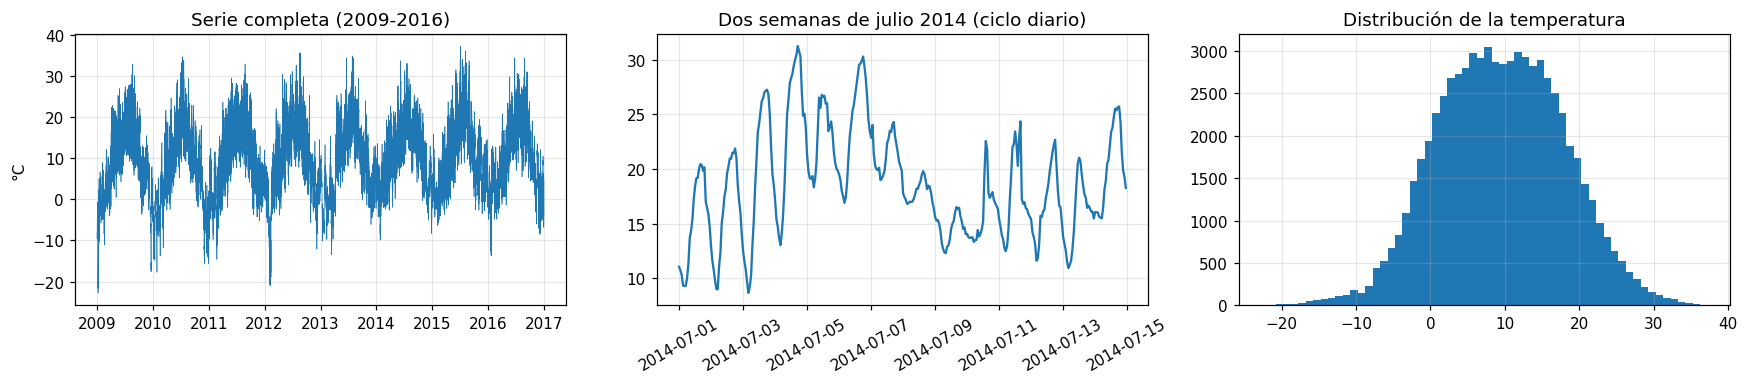

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].plot(df["fecha"], df["temp"], lw=0.4)
ax[0].set_title("Serie completa (2009-2016)"); ax[0].set_ylabel("°C")
m = df[(df["fecha"] >= "2014-07-01") & (df["fecha"] < "2014-07-15")]
ax[1].plot(m["fecha"], m["temp"]); ax[1].set_title("Dos semanas de julio 2014 (ciclo diario)")
ax[1].tick_params(axis="x", rotation=30)
ax[2].hist(df["temp"], bins=60); ax[2].set_title("Distribución de la temperatura")
plt.tight_layout(); savefig("01_eda"); plt.show()

## 3. Preprocesamiento

1. **Variables de entrada (5 por paso de tiempo):** la temperatura y una codificación cíclica de la **hora del día** y del **día del año** (seno y coseno). Así el modelo conoce la posición temporal sin tratarla como un número lineal (la hora 23 está cerca de la 0).
2. **Partición cronológica** 70 % / 15 % / 15 % (entrenamiento / validación / prueba). No se mezclan al azar para **evitar fuga de información** del futuro al pasado.
3. **Normalización (z-score)** con media y desviación calculadas **solo con el conjunto de entrenamiento**.
4. **Ventanas deslizantes:** cada muestra es `X ∈ R^(72×5)` y su objetivo `y ∈ R^24` (temperatura normalizada de las siguientes 24 h).

In [ ]:
LOOKBACK, HORIZON = 72, 24
BATCH = 256

temp = df["temp"].values.astype(np.float64)
hour = df["fecha"].dt.hour.values
doy = df["fecha"].dt.dayofyear.values

n = len(temp)
i_tr, i_va = int(n * 0.70), int(n * 0.85)

mu, sd = temp[:i_tr].mean(), temp[:i_tr].std()      # solo con entrenamiento
temp_s = (temp - mu) / sd
feats = np.column_stack([
    temp_s,
    np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
    np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25),
])
N_FEATS = feats.shape[1]

def make_windows(f, target, lookback, horizon):
    k = len(f) - lookback - horizon + 1
    ix = np.arange(k)[:, None] + np.arange(lookback)[None, :]
    iy = np.arange(k)[:, None] + lookback + np.arange(horizon)[None, :]
    return f[ix].astype(np.float32), target[iy].astype(np.float32)

Xtr, ytr = make_windows(feats[:i_tr], temp_s[:i_tr], LOOKBACK, HORIZON)
Xva, yva = make_windows(feats[i_tr:i_va], temp_s[i_tr:i_va], LOOKBACK, HORIZON)
Xte, yte = make_windows(feats[i_va:], temp_s[i_va:], LOOKBACK, HORIZON)

print(f"media={mu:.2f} °C  desv={sd:.2f} °C")
print("train:", Xtr.shape, ytr.shape, "| val:", Xva.shape, "| test:", Xte.shape)

train_loader = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)), batch_size=BATCH, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.from_numpy(Xva), torch.from_numpy(yva)), batch_size=1024)

media=9.11 °C  desv=8.65 °C
train: (48968, 72, 5) (48968, 24) | val: (10419, 72, 5) | test: (10419, 72, 5)


## 4. Modelos

**Línea base de referencia (sin aprendizaje):** *persistencia* — se predice que la temperatura de las próximas 24 h será igual a la última observada.

**Modelo A — GRU:** una GRU lee la ventana de 72 h; el último estado oculto alimenta una capa densa que produce las 24 predicciones.

**Modelo B — GRU + atención aditiva:** además del último estado, se calcula un **vector de contexto** que pondera todos los estados ocultos de la ventana:

$$e_t = v^{\top}\tanh(W_h h_t + W_q q),\qquad \alpha = \operatorname{softmax}(e),\qquad c=\sum_t \alpha_t h_t$$

donde $q$ es el último estado oculto (la *query*) y $h_t$ son los estados de cada hora (*keys/values*). La capa final recibe $[c ; q]$.

In [ ]:
class AdditiveAttention(nn.Module):
    """Atención aditiva de Bahdanau: puntaje = v^T tanh(W_h h_t + W_q q)."""
    def __init__(self, hidden):
        super().__init__()
        self.W_h = nn.Linear(hidden, hidden, bias=False)
        self.W_q = nn.Linear(hidden, hidden)
        self.v = nn.Linear(hidden, 1, bias=False)

    def forward(self, query, states):               # query (B,H) · states (B,T,H)
        e = self.v(torch.tanh(self.W_h(states) + self.W_q(query).unsqueeze(1))).squeeze(-1)   # (B,T)
        w = torch.softmax(e, dim=-1)                                                           # pesos de atención
        context = torch.bmm(w.unsqueeze(1), states).squeeze(1)                                 # (B,H)
        return context, w


class GRUForecaster(nn.Module):
    def __init__(self, n_feats, hidden=64, horizon=24, use_attention=True, dropout=0.1):
        super().__init__()
        self.use_attention = use_attention
        self.gru = nn.GRU(n_feats, hidden, batch_first=True)
        self.attn = AdditiveAttention(hidden) if use_attention else None
        in_dim = hidden * 2 if use_attention else hidden
        self.head = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, horizon))

    def forward(self, x, return_attn=False):
        states, h_n = self.gru(x)                   # states (B,T,H) · h_n (1,B,H)
        q = h_n[-1]
        w = None
        if self.use_attention:
            ctx, w = self.attn(q, states)
            q = torch.cat([ctx, q], dim=-1)
        out = self.head(q)
        return (out, w) if return_attn else out

model_gru = GRUForecaster(N_FEATS, use_attention=False, horizon=HORIZON)
model_att = GRUForecaster(N_FEATS, use_attention=True, horizon=HORIZON)
print(model_att)

GRUForecaster(
  (gru): GRU(5, 64, batch_first=True)
  (attn): AdditiveAttention(
    (W_h): Linear(in_features=64, out_features=64, bias=False)
    (W_q): Linear(in_features=64, out_features=64, bias=True)
    (v): Linear(in_features=64, out_features=1, bias=False)
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=24, bias=True)
  )
)


## 5. Entrenamiento
Optimizador Adam, pérdida MSE, *gradient clipping*, reducción de la tasa de aprendizaje en meseta y *early stopping* sobre la pérdida de validación. **Usa GPU (T4) para que tarde pocos minutos.**

In [ ]:
def train_model(model, name, epochs=30, lr=1e-3, patience=6):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    loss_fn = nn.MSELoss()
    hist = {"train": [], "val": []}
    best, best_state, wait = float("inf"), None, 0
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"[{name}] parámetros entrenables: {n_params:,}")
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl, cnt = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tl += loss.item() * len(xb); cnt += len(xb)
        model.eval(); vl, vc = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vl += loss_fn(model(xb), yb).item() * len(xb); vc += len(xb)
        tl, vl = tl / cnt, vl / vc
        hist["train"].append(tl); hist["val"].append(vl); sched.step(vl)
        print(f"  época {ep:02d} | train MSE {tl:.4f} | val MSE {vl:.4f}")
        if vl < best - 1e-5:
            best, wait = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f"  early stopping en la época {ep}"); break
    model.load_state_dict(best_state)
    print(f"[{name}] mejor val MSE = {best:.4f} | tiempo = {time.time() - t0:.0f} s")
    return hist

@torch.no_grad()
def predict(model, X, bs=1024):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.from_numpy(X[i:i + bs]).to(device)).cpu().numpy())
    return np.concatenate(out)

def to_c(a):                       # de z-score a °C
    return a * sd + mu

def evaluate(pred_s, true_s):
    p, t = to_c(pred_s), to_c(true_s)
    err = p - t
    return {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean())),
            "MAE_por_hora": np.abs(err).mean(0)}

In [ ]:
histories = {}
histories["GRU"] = train_model(model_gru, "GRU")
histories["GRU + atención"] = train_model(model_att, "GRU + atención")

[GRU] parámetros entrenables: 19,352
  época 01 | train MSE 0.2669 | val MSE 0.1054
  época 02 | train MSE 0.1133 | val MSE 0.0991
  época 03 | train MSE 0.1062 | val MSE 0.0958
  época 04 | train MSE 0.1023 | val MSE 0.0935
  época 05 | train MSE 0.0984 | val MSE 0.0922
  época 06 | train MSE 0.0960 | val MSE 0.0948
  época 07 | train MSE 0.0936 | val MSE 0.0888
  época 08 | train MSE 0.0922 | val MSE 0.0886
  época 09 | train MSE 0.0912 | val MSE 0.0881
  época 10 | train MSE 0.0905 | val MSE 0.0865
  época 11 | train MSE 0.0903 | val MSE 0.0890
  época 12 | train MSE 0.0897 | val MSE 0.0883
  época 13 | train MSE 0.0893 | val MSE 0.0864
  época 14 | train MSE 0.0898 | val MSE 0.0875
  época 15 | train MSE 0.0882 | val MSE 0.0869
  época 16 | train MSE 0.0887 | val MSE 0.0866
  época 17 | train MSE 0.0874 | val MSE 0.0860
  época 18 | train MSE 0.0874 | val MSE 0.0860
  época 19 | train MSE 0.0871 | val MSE 0.0865
  época 20 | train MSE 0.0873 | val MSE 0.0858
  época 21 | train MSE 

## 6. Evaluación en el conjunto de prueba
Las métricas se reportan en **°C** (se revierte la normalización): **MAE** y **RMSE** promediados sobre las 24 horas predichas.

In [ ]:
results = {}
pred_persist = np.repeat(Xte[:, -1, 0:1], HORIZON, axis=1)          # última temperatura repetida
results["Persistencia"] = evaluate(pred_persist, yte)
pred_gru = predict(model_gru, Xte);  results["GRU"] = evaluate(pred_gru, yte)
pred_att = predict(model_att, Xte);  results["GRU + atención"] = evaluate(pred_att, yte)

tabla = pd.DataFrame({k: {"MAE (°C)": v["MAE"], "RMSE (°C)": v["RMSE"]} for k, v in results.items()}).T.round(3)
display(tabla)

json.dump({k: {"MAE": v["MAE"], "RMSE": v["RMSE"]} for k, v in results.items()}, open("resultados_notebook1.json", "w"), indent=2)

,MAE (°C),RMSE (°C)
Persistencia,3.158,4.271
GRU,1.814,2.398
GRU + atención,1.813,2.400


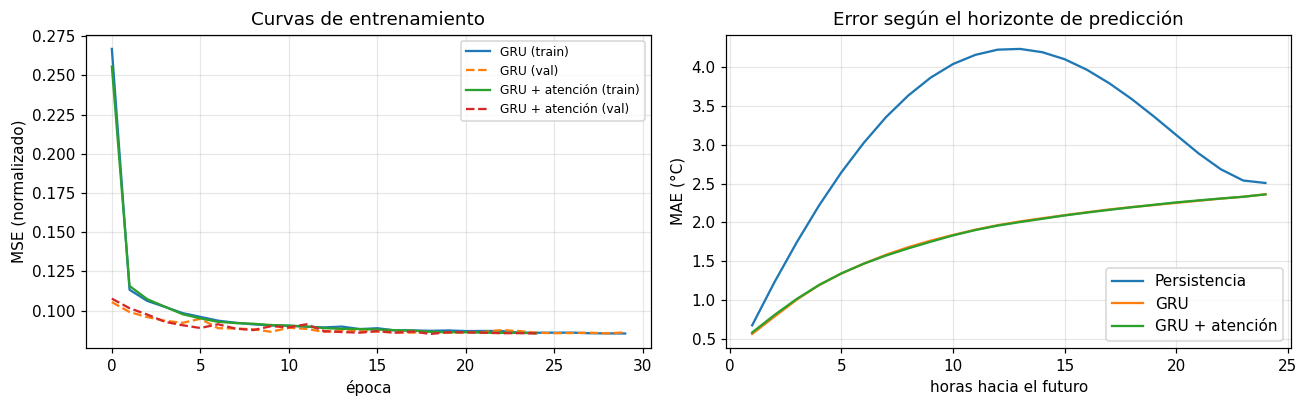

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, h in histories.items():
    ax[0].plot(h["train"], label=f"{name} (train)"); ax[0].plot(h["val"], "--", label=f"{name} (val)")
ax[0].set_xlabel("época"); ax[0].set_ylabel("MSE (normalizado)"); ax[0].set_title("Curvas de entrenamiento"); ax[0].legend(fontsize=8)
for name, r in results.items():
    ax[1].plot(range(1, HORIZON + 1), r["MAE_por_hora"], label=name)
ax[1].set_xlabel("horas hacia el futuro"); ax[1].set_ylabel("MAE (°C)"); ax[1].set_title("Error según el horizonte de predicción"); ax[1].legend()
plt.tight_layout(); savefig("curvas_y_error_horizonte"); plt.show()

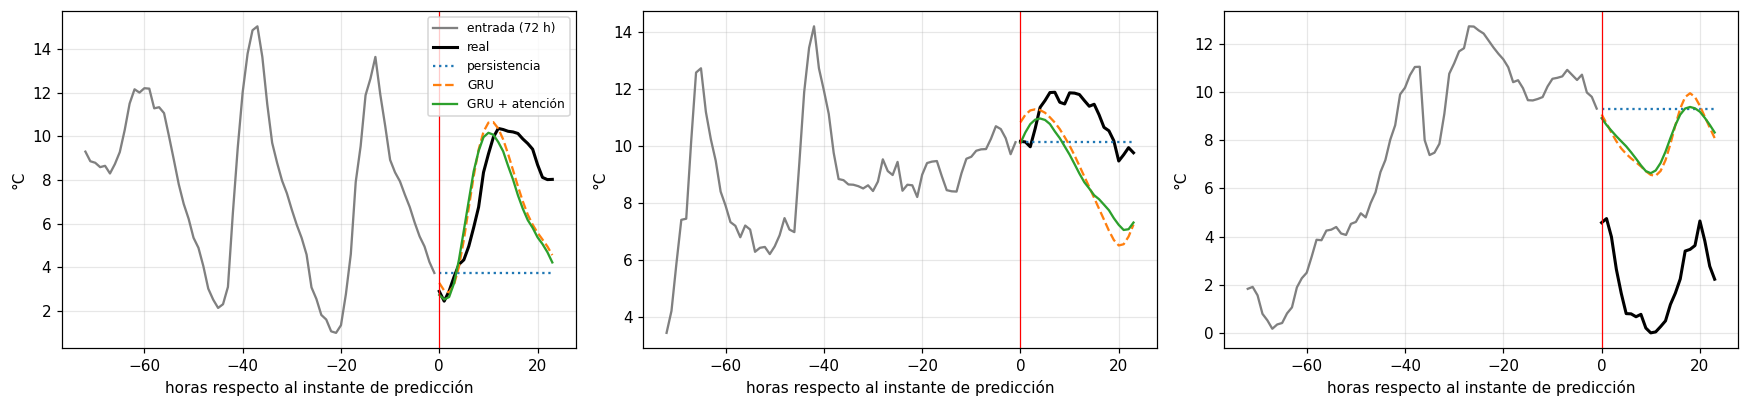

In [ ]:
idx = [200, 1500, 3000]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=False)
for ax, i in zip(axes, idx):
    hist_c = to_c(Xte[i, :, 0])
    ax.plot(range(-LOOKBACK, 0), hist_c, color="gray", label="entrada (72 h)")
    ax.plot(range(0, HORIZON), to_c(yte[i]), "k", lw=2, label="real")
    ax.plot(range(0, HORIZON), to_c(pred_persist[i]), ":", label="persistencia")
    ax.plot(range(0, HORIZON), to_c(pred_gru[i]), "--", label="GRU")
    ax.plot(range(0, HORIZON), to_c(pred_att[i]), label="GRU + atención")
    ax.axvline(0, color="red", lw=0.8); ax.set_xlabel("horas respecto al instante de predicción"); ax.set_ylabel("°C")
axes[0].legend(fontsize=8); plt.tight_layout(); savefig("pronosticos_ejemplo"); plt.show()

## 7. Análisis de los pesos de atención
La atención es **interpretable**: los pesos $\alpha_t$ indican qué horas de la ventana consideró más relevantes el modelo. Se muestra (a) el peso promedio por posición en toda la prueba y (b) un mapa de calor de varias muestras.

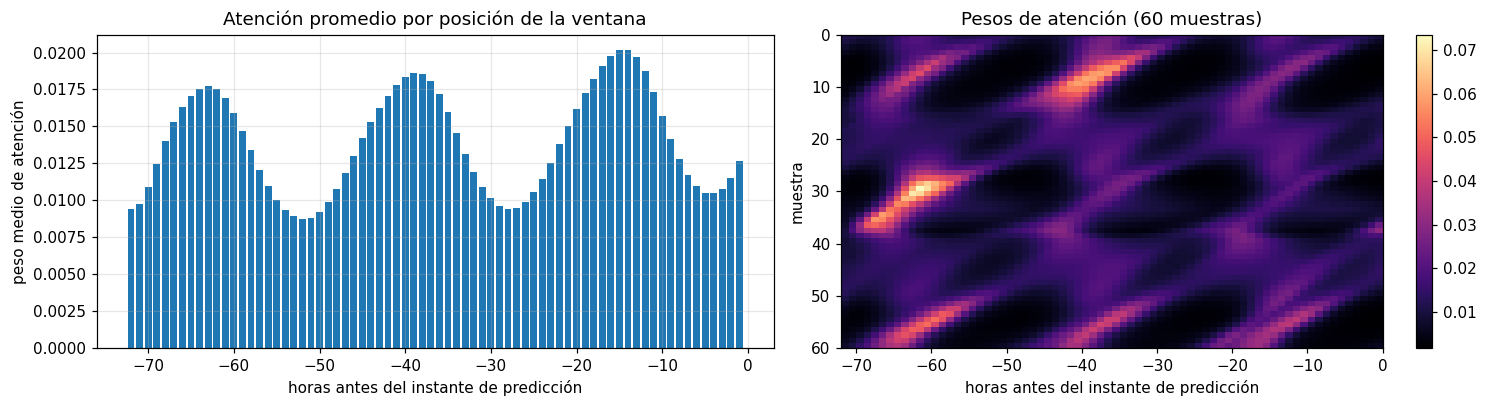

Posiciones con mayor atención media (horas antes): [-17, -16, -15, -14, -13]


In [ ]:
model_att.eval()
with torch.no_grad():
    _, W = model_att(torch.from_numpy(Xte[:3000]).to(device), return_attn=True)
W = W.cpu().numpy()                                  # (muestras, 72)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].bar(range(-LOOKBACK, 0), W.mean(0), color="tab:blue")
ax[0].set_xlabel("horas antes del instante de predicción"); ax[0].set_ylabel("peso medio de atención")
ax[0].set_title("Atención promedio por posición de la ventana")
im = ax[1].imshow(W[:60], aspect="auto", cmap="magma", extent=[-LOOKBACK, 0, 60, 0])
ax[1].set_xlabel("horas antes del instante de predicción"); ax[1].set_ylabel("muestra"); ax[1].set_title("Pesos de atención (60 muestras)")
ax[1].grid(False); plt.colorbar(im, ax=ax[1]); plt.tight_layout(); savefig("atencion_pesos"); plt.show()

top = np.argsort(W.mean(0))[::-1][:5] - LOOKBACK
print("Posiciones con mayor atención media (horas antes):", sorted(top.tolist()))